# Funnels and Markov chains: transition counts

A user session is a path through states: landing → product → cart → checkout → purchase, with returns, repeats
and exits along the way. Model it as a first-order Markov chain with transition matrix $P$: the next state
depends only on the current one. The likelihood of a set of observed paths is

$$\prod_{\text{paths}}\prod_{t} P_{s_{t-1}, s_t} = \prod_{i,j} P_{ij}^{N_{ij}},$$

so the matrix of transition counts $N_{ij}$ is sufficient, however many sessions there are and however long
they ran. Each row is a multinomial, $N_{i\cdot} \sim \text{Multinomial}(n_i, P_{i\cdot})$, and a Dirichlet
prior per row is conjugate.

A *funnel* is the special case with no returns or repeats: from each stage a user either advances one stage
or leaves. Each row then has two outcomes, the multinomials become binomials, $n_{k+1} \sim
\text{Binomial}(n_k, p_k)$, and the sufficient statistic is the head-count reaching each stage. Product
dashboards usually report these head-counts, so they are often the only data available.

The notebook shows what the chain is used for (the probability that a session ends in a purchase, and which
step is worth improving), then compares raw-row and count fits for the chain and for a cohort funnel.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(404)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)
TIMINGS = []


def timed_fit(model, label, n_rows, case, kind, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    TIMINGS.append({"case": case, "kind": kind, "model": label, "rows": int(n_rows),
                    "wall_s": round(secs, 2), "min_ess_per_s": round(ess / secs, 1)})
    return idata


def save_timings(name):
    Path("timings").mkdir(exist_ok=True)
    Path(f"timings/{name}.json").write_text(json.dumps(TIMINGS, indent=1))
    return pd.DataFrame(TIMINGS).drop(columns="case")

## Sessions as a Markov chain

Four transient states, two absorbing ones (purchase, exit), and two traffic sources with different behaviour.
Some moves are impossible (landing → cart, for example), and the prior respects that: each row has a
Dirichlet over its allowed destinations only. We simulate 20,000 sessions and keep every transition with its
session id.

In [2]:
STATES = ["landing", "product", "cart", "checkout", "purchase", "exit"]
SOURCES = ["paid", "organic"]
TRANSIENT = 4
ALLOWED = {0: [1, 5], 1: [0, 1, 2, 5], 2: [1, 2, 3, 5], 3: [2, 4, 5]}
P_true = np.array([
    [[0.00, 0.55, 0.00, 0.00, 0.00, 0.45],
     [0.20, 0.35, 0.18, 0.00, 0.00, 0.27],
     [0.00, 0.30, 0.05, 0.45, 0.00, 0.20],
     [0.00, 0.00, 0.15, 0.00, 0.60, 0.25]],
    [[0.00, 0.65, 0.00, 0.00, 0.00, 0.35],
     [0.15, 0.40, 0.20, 0.00, 0.00, 0.25],
     [0.00, 0.25, 0.05, 0.50, 0.00, 0.20],
     [0.00, 0.00, 0.10, 0.00, 0.70, 0.20]],
])
n_sess = 20_000
source = rng.integers(0, 2, n_sess)

rec = {"session": [], "step": [], "source": [], "from": [], "to": []}
state = np.zeros(n_sess, int)
active = np.ones(n_sess, bool)
step = 0
while active.any():
    idx = np.flatnonzero(active)
    probs = P_true[source[idx], state[idx]]
    nxt = (probs.cumsum(1) > rng.random(len(idx))[:, None]).argmax(1)
    for key, val in [("session", idx), ("step", np.full(len(idx), step)), ("source", source[idx]),
                     ("from", state[idx]), ("to", nxt)]:
        rec[key].append(val)
    state[idx] = nxt
    active[idx] = nxt < TRANSIENT
    step += 1
transitions = (pd.DataFrame({k: np.concatenate(v) for k, v in rec.items()})
               .sort_values(["session", "step"]).reset_index(drop=True))

N = np.zeros((2, TRANSIENT, len(STATES)), int)
np.add.at(N, (transitions.source, transitions["from"], transitions.to), 1)
print(f"{n_sess:,} sessions -> {len(transitions):,} transitions -> {sum(len(a) for a in ALLOWED.values()) * 2} counts")
pd.DataFrame(N[0], index=STATES[:TRANSIENT], columns=STATES)

20,000 sessions -> 58,669 transitions -> 26 counts


,landing,product,cart,checkout,purchase,exit
landing,0,6658,0,0,0,5551
product,2261,3934,2041,0,0,3008
cart,0,652,119,1074,0,488
checkout,0,0,173,0,633,268


## Raw transitions vs counts

The quantity of interest is the probability that a session starting on the landing page ends in a purchase.
Split $P$ into moves between transient states, $Q$, and moves into absorbing states, $R$. The absorption
probabilities are $B = (I-Q)^{-1}R$; a later section explains where this comes from. Both models compute it as
a deterministic.

The raw-row model adds each transition's $\log P_{\text{from},\text{to}}$ with `pm.Potential`. (Passing the
full row $P_{\text{from},\cdot}$ to `pm.Categorical` per transition is the same likelihood but about six times
slower, because it builds a transitions × states array at every gradient step.) The compressed model has one
multinomial per row of the count matrix.

In [3]:
coords = {"source": SOURCES, "from": STATES[:TRANSIENT], "to": STATES}


def transition_prior():
    full = pt.zeros((2, TRANSIENT, len(STATES)))
    rows = {}
    for i, allowed in ALLOWED.items():
        rows[i] = pm.Dirichlet(f"P_{STATES[i]}", a=np.ones(len(allowed)), shape=(2, len(allowed)))
        full = pt.set_subtensor(full[:, i, allowed], rows[i])
    P = pm.Deterministic("P", full, dims=("source", "from", "to"))
    B = [pt.linalg.solve(pt.eye(TRANSIENT) - P[s, :, :TRANSIENT], P[s, :, TRANSIENT:]) for s in range(2)]
    pm.Deterministic("p_purchase", pt.stack([b[0, 0] for b in B]), dims="source")
    return P, rows


with pm.Model(coords=coords) as mc_full:
    P, _ = transition_prior()
    pm.Potential("transitions_loglik", pm.math.log(
        P[transitions.source.values, transitions["from"].values, transitions.to.values]).sum())

with pm.Model(coords=coords) as mc_suff:
    P, rows = transition_prior()
    for i, allowed in ALLOWED.items():
        Ni = N[:, i][:, allowed]
        pm.Multinomial(f"N_{STATES[i]}", n=Ni.sum(-1), p=rows[i], observed=Ni)

idata_mf = timed_fit(mc_full, "Markov: log P per transition", len(transitions), "Markov chain", "raw")
idata_ms = timed_fit(mc_suff, "Markov: Multinomial on N_ij", 2 * TRANSIENT, "Markov chain", "compressed")

NUTS[nutpie]: [P_landing, P_product, P_cart, P_checkout]
/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:90: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / 

## The fitted chain

The heatmap shows the posterior transition probabilities with 89% intervals. Grey cells are impossible moves.
The back-edges (product → landing, cart → product, checkout → cart) are what make this a chain rather than a
funnel: a sizeable share of sessions moves backwards before converting or leaving.

In [4]:
P_draws = idata_ms.posterior["P"].values.reshape(-1, 2, TRANSIENT, len(STATES))

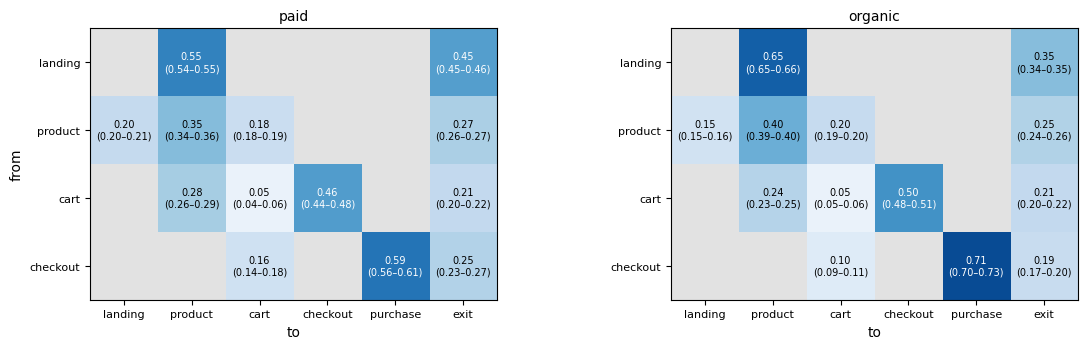

In [5]:
#| label: fig-funnel-matrix
#| fig-cap: "Posterior mean transition probabilities (89% interval) from the transition-count fit, by traffic source. Grey cells are impossible moves."
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
mask = np.ones((TRANSIENT, len(STATES)), bool)
for i, allowed in ALLOWED.items():
    mask[i, allowed] = False
for s, ax in enumerate(axes):
    mean = P_draws[:, s].mean(0)
    lo, hi = np.quantile(P_draws[:, s], [0.055, 0.945], 0)
    ax.imshow(np.ma.masked_where(mask, mean), cmap="Blues", vmin=0, vmax=0.8)
    ax.imshow(np.ma.masked_where(~mask, np.ones_like(mean)), cmap="Greys", vmin=0, vmax=5)
    for i in range(TRANSIENT):
        for j in range(len(STATES)):
            if not mask[i, j]:
                ax.text(j, i, f"{mean[i, j]:.2f}\n({lo[i, j]:.2f}–{hi[i, j]:.2f})", ha="center", va="center",
                        fontsize=7, color="white" if mean[i, j] > 0.45 else "black")
    ax.set_xticks(range(len(STATES)), STATES, fontsize=8)
    ax.set_yticks(range(TRANSIENT), STATES[:TRANSIENT], fontsize=8)
    ax.set_xlabel("to")
    ax.set_title(SOURCES[s], fontsize=10)
axes[0].set_ylabel("from")
plt.tight_layout()
plt.show()

## Why the purchase probability needs a matrix inverse

The matrix $N = (I-Q)^{-1}$ is the **fundamental matrix** of the chain: entry $N_{ij}$ is the expected number
of visits to state $j$ for a session that starts in state $i$. Its first row counts every visit a landing-page
session makes, including return trips. The probability of purchase is the expected number of checkout visits
times the probability that a checkout visit ends in purchase, $B_{\text{landing},\text{purchase}} =
N_{\text{landing},\text{checkout}}\,P_{\text{checkout},\text{purchase}}$.

Multiplying the forward step rates instead (landing → product → cart → checkout → purchase) counts only sessions
that go straight through, and so understates the purchase probability.

The fundamental matrix also answers which step is worth improving. For each forward step we move 5 percentage
points of probability from "exit" to that step, in every posterior draw, and recompute the purchase probability.

In [6]:
Q, R = P_draws[..., :TRANSIENT], P_draws[..., TRANSIENT:]
Nfund = np.linalg.inv(np.eye(TRANSIENT) - Q)                         # (draw, source, 4, 4)
B = Nfund @ R
p_purchase = B[..., 0, 0]
forward = P_draws[..., 0, 1] * P_draws[..., 1, 2] * P_draws[..., 2, 3] * P_draws[..., 3, 4]

EDGES = [(0, 1), (1, 2), (2, 3), (3, 4)]
whatif = {}
for i, j in EDGES:
    P2 = P_draws.copy()
    P2[..., i, j] += 0.05
    P2[..., i, 5] -= 0.05
    B2 = np.linalg.inv(np.eye(TRANSIENT) - P2[..., :TRANSIENT]) @ P2[..., TRANSIENT:]
    whatif[f"{STATES[i]} → {STATES[j]}"] = B2[..., 0, 0] - p_purchase

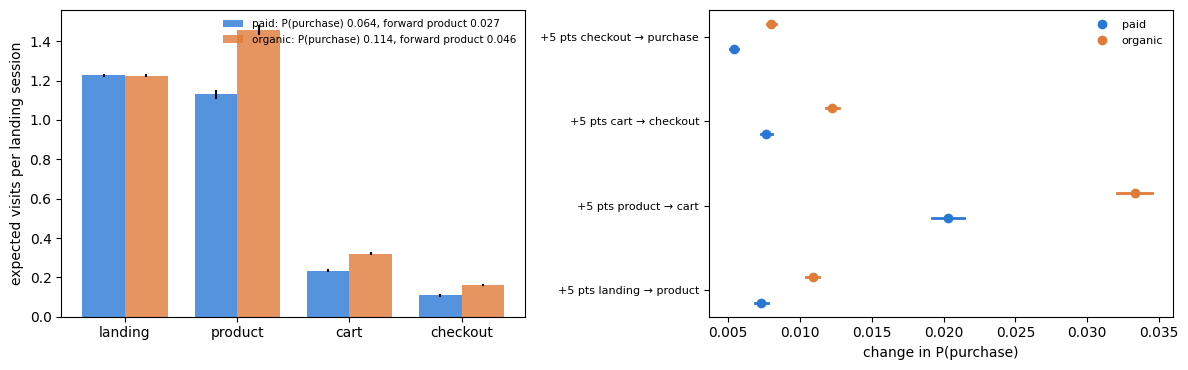

In [7]:
#| label: fig-funnel-whatif
#| fig-cap: "Left: expected visits to each state per landing-page session (fundamental matrix, posterior mean and 89% interval); the legend compares the purchase probability from the chain with the product of forward step rates. Right: posterior change in the purchase probability from moving 5 percentage points from exit to each forward step (mean and 89% interval)."
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
w = 0.38
cols = ["#2a78d6", "#e07b39"]
for s in range(2):
    v = Nfund[:, s, 0, :]
    m = v.mean(0)
    lo, hi = np.quantile(v, [0.055, 0.945], 0)
    ax.bar(np.arange(TRANSIENT) + (s - 0.5) * w, m, w, yerr=[m - lo, hi - m], color=cols[s], alpha=0.8,
           label=f"{SOURCES[s]}: P(purchase) {p_purchase[:, s].mean():.3f}, forward product {forward[:, s].mean():.3f}")
ax.set_xticks(range(TRANSIENT), STATES[:TRANSIENT])
ax.set_ylabel("expected visits per landing session")
ax.legend(frameon=False, fontsize=7.5, loc="upper right")
ax = axes[1]
names = list(whatif)
for s in range(2):
    for r, name in enumerate(names):
        d = whatif[name][:, s]
        y0 = r + (s - 0.5) * 0.3
        ax.plot(np.quantile(d, [0.055, 0.945]), [y0, y0], color=cols[s], lw=2)
        ax.plot(d.mean(), y0, "o", color=cols[s], label=SOURCES[s] if r == 0 else None)
ax.set_yticks(range(len(names)), [f"+5 pts {n}" for n in names], fontsize=8)
ax.set_xlabel("change in P(purchase)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
pd.DataFrame({name: [f"{whatif[name][:, s].mean():+.4f}" for s in range(2)] for name in names}, index=SOURCES).T

,paid,organic
landing → product,+0.0073,+0.0109
product → cart,+0.0203,+0.0333
cart → checkout,+0.0076,+0.0122
checkout → purchase,+0.0054,+0.0080


Improving checkout → purchase is the smallest lever, even though it is the last step. Moving $\delta$ of probability
from exit to a step $i \to j$ changes the purchase probability by approximately
$N_{\text{landing},i}\,\delta\,B_{j,\text{purchase}}$: expected visits to state $i$, times $\delta$, times the purchase
probability from the new destination. Product pages are visited more than once per session on average, and a
session that reaches the cart goes on to buy between a third and a half of the time, so product → cart is worth about four
times as much as checkout → purchase, which applies to only about 0.1 checkout visits per session.

## Does the Markov assumption hold?

The counts $N_{ij}$ are sufficient only if the chain is first-order. The raw sessions can check this before
we compress. Two checks:

1. **Second-order counts.** If the chain is first-order, the probability of moving from cart to checkout should
   not depend on where the session was before the cart.
2. **Session length.** Simulate sessions from posterior draws of $P$ and compare their length distribution with
   the observed one.

In this simulation the chain is first-order by construction, so both checks should pass. In real data, these
are the checks that justify the compression.

In [9]:
transitions["prev"] = transitions.groupby("session")["from"].shift(1)
from_cart = transitions[(transitions["from"] == 2) & transitions.prev.notna()]
second = from_cart.assign(to_checkout=(from_cart.to == 3)).groupby("prev").to_checkout.agg(["sum", "size"])
second.index = [STATES[int(i)] for i in second.index]

obs_len = transitions.groupby("session").size()
L = np.arange(1, 16)
obs_share = np.array([(obs_len == l).mean() for l in L])


def simulate_lengths(P, n):
    st, length, act = np.zeros(n, int), np.zeros(n, int), np.ones(n, bool)
    src = rng.integers(0, 2, n)
    while act.any():
        idx = np.flatnonzero(act)
        nxt = (P[src[idx], st[idx]].cumsum(1) > rng.random(len(idx))[:, None]).argmax(1)
        st[idx], length[idx] = nxt, length[idx] + 1
        act[idx] = nxt < TRANSIENT
    return length


ppc = np.array([[(lens == l).mean() for l in L] for lens in
                (simulate_lengths(P_draws[d], 2000) for d in rng.choice(len(P_draws), 200, replace=False))])

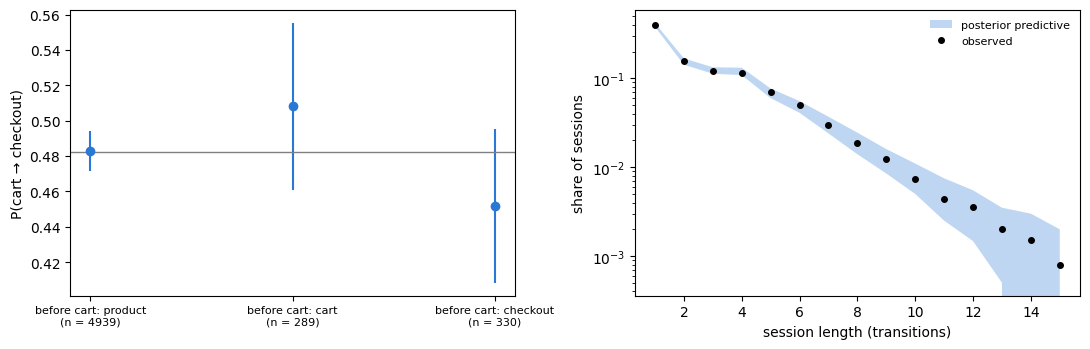

In [10]:
#| label: fig-funnel-check
#| fig-cap: "Checks of the first-order Markov assumption on the raw sessions. Left: probability of moving from cart to checkout, split by the state before the cart (Beta posterior, 89% interval); the grey line is the pooled rate. Right: observed session lengths (points) against lengths simulated from 200 posterior draws of P (89% band)."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for r, (h, row) in enumerate(second.iterrows()):
    dr = rng.beta(1 + row["sum"], 1 + row["size"] - row["sum"], 20_000)
    ax.errorbar(r, dr.mean(), yerr=[[dr.mean() - np.quantile(dr, .055)], [np.quantile(dr, .945) - dr.mean()]],
                fmt="o", color="#2a78d6")
ax.axhline((from_cart.to == 3).mean(), color="grey", lw=1)
ax.set_xticks(range(len(second)), [f"before cart: {h}\n(n = {int(n)})" for h, n in zip(second.index, second["size"])], fontsize=8)
ax.set_ylabel("P(cart → checkout)")
ax = axes[1]
lo, hi = np.quantile(ppc, [0.055, 0.945], 0)
ax.fill_between(L, lo, hi, color="#2a78d6", alpha=0.3, lw=0, label="posterior predictive")
ax.plot(L, obs_share, "ko", ms=4, label="observed")
ax.set_yscale("log")
ax.set_xlabel("session length (transitions)")
ax.set_ylabel("share of sessions")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## A cohort funnel

12 weekly sign-up cohorts pass through visit → sign-up → activate → pay. This is the chain above with every
back-edge and repeat removed: from each stage a user advances or leaves. Step conversion rates vary across
cohorts, so we pool them on the logit scale with a hierarchical prior. The raw data is one Bernoulli per user
per stage reached; the compressed data is a 12 × 4 table of head-counts.

In [11]:
n_coh, steps = 12, ["sign-up", "activate", "pay"]
mu_true, sd_true = np.array([-1.2, 0.3, -1.0]), np.array([0.15, 0.25, 0.20])
logit_p = mu_true[:, None] + sd_true[:, None] * rng.normal(size=(3, n_coh))
p_true = 1 / (1 + np.exp(-logit_p))
visits = rng.integers(1_500, 3_500, n_coh)

rows_ = []
reached = [np.repeat(np.arange(n_coh), visits)]
for k in range(3):
    coh = reached[-1]
    y = rng.binomial(1, p_true[k, coh])
    rows_.append(pd.DataFrame({"cohort": coh, "step": k, "y": y}))
    reached.append(coh[y == 1])
users = pd.concat(rows_, ignore_index=True)

heads = np.array([np.bincount(r, minlength=n_coh) for r in reached])   # (stage, cohort) head-counts
print(f"{visits.sum():,} visitors -> {len(users):,} user-step rows -> {heads.size} head-counts")
pd.DataFrame(heads[:, :6], index=["visit"] + steps, columns=[f"wk{c + 1}" for c in range(6)])

30,385 visitors -> 42,096 user-step rows -> 48 head-counts


,wk1,wk2,wk3,wk4,wk5,wk6
visit,3333,2429,2902,2365,2577,2456
sign-up,917,439,657,652,701,657
activate,486,235,385,373,309,352
pay,106,61,121,104,62,87


In [12]:
fcoords = {"step": steps, "cohort": np.arange(n_coh)}


def funnel_prior():
    mu = pm.Normal("mu", 0, 1.5, dims="step")
    sd = pm.HalfNormal("sd", 0.5, dims="step")
    z = pm.Normal("z", 0, 1, dims=("step", "cohort"))
    return pm.Deterministic("p", pm.math.invlogit(mu[:, None] + sd[:, None] * z), dims=("step", "cohort"))


with pm.Model(coords=fcoords) as fun_full:
    p = funnel_prior()
    pm.Bernoulli("y", p=p[users.step.values, users.cohort.values], observed=users.y.values)

with pm.Model(coords=fcoords) as fun_suff:
    p = funnel_prior()
    pm.Binomial("n_next", n=heads[:-1], p=p, observed=heads[1:])

idata_ff = timed_fit(fun_full, "Funnel: Bernoulli per user-step", len(users), "Funnel", "raw")
idata_fs = timed_fit(fun_suff, "Funnel: Binomial on head-counts", heads[:-1].size, "Funnel", "compressed")

NUTS[nutpie]: [mu, sd, z]
NUTS[nutpie]: [mu, sd, z]


The end-to-end conversion of a cohort is the product of its step conversions. The hierarchical prior pulls
each cohort's step rates toward the population mean, more strongly for small cohorts and noisy steps. The
figure shows the end-to-end rate per cohort and, for the last step, how far each cohort's estimate moves from
its raw ratio.

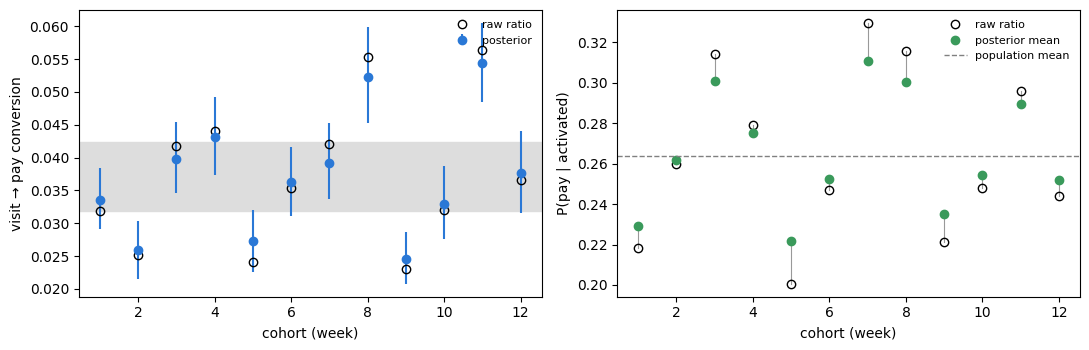

In [13]:
#| label: fig-funnel-cohorts
#| fig-cap: "Left: end-to-end conversion (visit to pay) per weekly cohort, posterior mean and 89% interval from the head-count fit, with raw ratios as open circles and the population-level rate as the grey band. Right: the activate → pay step per cohort, raw ratio (open) and posterior mean (filled), joined by a line to show partial pooling."
pf = idata_fs.posterior
p_draws = pf["p"].values.reshape(-1, 3, n_coh)
e2e = p_draws.prod(1)
pop = (1 / (1 + np.exp(-pf["mu"].values.reshape(-1, 3)))).prod(1)
wk = np.arange(1, n_coh + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.axhspan(*np.quantile(pop, [0.055, 0.945]), color="#dddddd")
lo, hi = np.quantile(e2e, [0.055, 0.945], 0)
ax.errorbar(wk, e2e.mean(0), yerr=[e2e.mean(0) - lo, hi - e2e.mean(0)], fmt="o", color="#2a78d6", label="posterior")
ax.plot(wk, heads[3] / heads[0], "o", mfc="none", color="k", label="raw ratio")
ax.set_xlabel("cohort (week)")
ax.set_ylabel("visit → pay conversion")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
raw_pay = heads[3] / heads[2]
post_pay = p_draws[:, 2].mean(0)
for c in range(n_coh):
    ax.plot([wk[c], wk[c]], [raw_pay[c], post_pay[c]], color="#999999", lw=0.8)
ax.plot(wk, raw_pay, "o", mfc="none", color="k", label="raw ratio")
ax.plot(wk, post_pay, "o", color="#3a9a5b", label="posterior mean")
ax.axhline(1 / (1 + np.exp(-pf["mu"].sel(step="pay").values.mean())), color="grey", lw=1, ls="--", label="population mean")
ax.set_xlabel("cohort (week)")
ax.set_ylabel("P(pay | activated)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

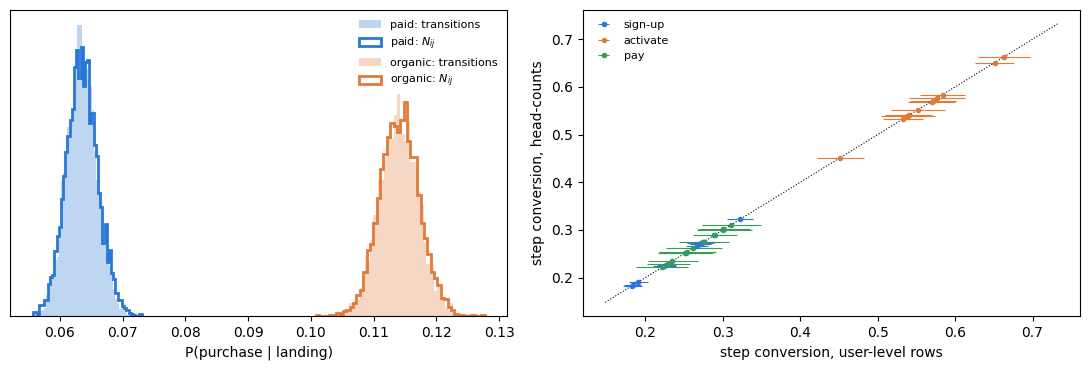

In [14]:
#| label: fig-funnel-equiv
#| fig-cap: "Left: posterior probability that a landing-page session ends in purchase, by traffic source, from every transition (filled) and from the transition-count matrix (line). Right: per-cohort step conversion posterior means from user-level rows against head-counts, with 89% intervals from the user-level fit; points on the diagonal mean the two fits agree."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for s, col in zip(SOURCES, cols):
    ax.hist(idata_mf.posterior["p_purchase"].sel(source=s).values.ravel(), bins=50, density=True,
            alpha=0.3, color=col, label=f"{s}: transitions")
    ax.hist(idata_ms.posterior["p_purchase"].sel(source=s).values.ravel(), bins=50, density=True,
            histtype="step", lw=2, color=col, label=f"{s}: $N_{{ij}}$")
ax.set_yticks([])
ax.set_xlabel("P(purchase | landing)")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
pfu, psu = idata_ff.posterior["p"], idata_fs.posterior["p"]
for k, col in zip(steps, ["#2a78d6", "#e07b39", "#3a9a5b"]):
    x, yv = pfu.sel(step=k), psu.sel(step=k)
    xm, ym = x.mean(("chain", "draw")), yv.mean(("chain", "draw"))
    xlo, xhi = x.quantile([0.055, 0.945], ("chain", "draw"))
    ax.errorbar(xm, ym, xerr=[xm - xlo, xhi - xm], fmt="o", ms=3, lw=0.8, color=col, label=k)
lims = [float(pfu.min()), float(pfu.max())]
ax.plot(lims, lims, "k:", lw=0.8)
ax.set_xlabel("step conversion, user-level rows")
ax.set_ylabel("step conversion, head-counts")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
#| label: tbl-funnel-speed
#| tbl-cap: "Transition-level and user-level likelihoods against their count summaries. The last column gives the posterior mean purchase probability (paid / organic) for the two Markov fits."
speed = save_timings("04_funnels_markov_chains")
speed["P(purchase) paid / organic"] = [
    " / ".join(f"{float(i.posterior['p_purchase'].sel(source=s).mean()):.4f}" for s in SOURCES)
    for i in (idata_mf, idata_ms)] + ["", ""]
speed

,kind,model,rows,wall_s,min_ess_per_s,P(purchase) paid / organic
0,raw,Markov: log P per transition,58669,16.35,160.8,0.0635 / 0.1140
1,compressed,Markov: Multinomial on N_ij,8,7.41,379.4,0.0635 / 0.1141
2,raw,Funnel: Bernoulli per user-step,42096,14.60,31.0,
3,compressed,Funnel: Binomial on head-counts,36,1.40,311.5,


## What compression gives up

- **The order of states within a session.** $N_{ij}$ is sufficient only for a first-order chain. If the next step
  depends on more history, check with second-order counts $N_{hij}$ (still a count tensor, just larger), as above.
- **Session-level heterogeneity.** A random effect shared by a user's transitions makes transitions from different
  users no longer interchangeable, and breaks sufficiency in the same way frailty does in survival models.
- **Per-user covariates** must be categorical to stratify the count tensor (source, device, region).